In [2]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '1'

import deepxde as dde 
dde.config.disable_xla_jit()

from deepxde.backend import tf

seed = 1234
dde.config.set_random_seed(seed)


Using backend: tensorflow

2022-11-09 18:04:11.671959: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcuda.so.1
2022-11-09 18:04:11.745710: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:24:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 18:04:11.745733: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 18:04:11.748152: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 18:04:11.748181: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11
2022-11-09 18:04:11.749029: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dyn

Enable just-in-time compilation with XLA.

Disable just-in-time compilation with XLA.



[1, 1000]
no uniform points
Compiling model...
'compile' took 0.000405 s



2022-11-09 18:04:12.795145: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-11-09 18:04:12.804457: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1733] Found device 0 with properties: 
pciBusID: 0000:24:00.0 name: Quadro RTX 8000 computeCapability: 7.5
coreClock: 1.77GHz coreCount: 72 deviceMemorySize: 47.46GiB deviceMemoryBandwidth: 625.94GiB/s
2022-11-09 18:04:12.812602: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1871] Adding visible gpu devices: 0
2022-11-09 18:04:12.812693: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcudart.so.11.0
2022-11-09 18:04:13.325233: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1258] Device interconnect StreamExecu

Training model...



2022-11-09 18:04:15.643871: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:176] None of the MLIR Optimization Passes are enabled (registered 2)
2022-11-09 18:04:15.670213: I tensorflow/core/platform/profile_utils/cpu_utils.cc:114] CPU Frequency: 3000030000 Hz
2022-11-09 18:04:15.797392: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublas.so.11
2022-11-09 18:04:16.244623: I tensorflow/stream_executor/platform/default/dso_loader.cc:53] Successfully opened dynamic library libcublasLt.so.11


Step      Train loss              Test loss               Test metric   
0         [1.80e+00, 7.55e-01]    [1.61e+00, 7.63e-01]    [1.49e+00]    
1000      [4.61e-03, 1.19e-02]    [5.28e-03, 1.24e-02]    [9.41e-01]    
2000      [2.36e-03, 6.29e-03]    [3.28e-03, 6.78e-03]    [9.74e-01]    
3000      [1.27e-03, 3.53e-03]    [2.08e-03, 3.90e-03]    [1.03e+00]    
4000      [6.61e-04, 1.80e-03]    [1.26e-03, 2.05e-03]    [1.14e+00]    
5000      [4.37e-04, 1.22e-03]    [8.84e-04, 1.46e-03]    [1.23e+00]    
6000      [3.24e-04, 1.03e-03]    [7.27e-04, 1.27e-03]    [1.28e+00]    
7000      [2.51e-04, 8.99e-04]    [6.10e-04, 1.14e-03]    [1.31e+00]    
8000      [2.04e-04, 7.95e-04]    [5.13e-04, 1.03e-03]    [1.34e+00]    
9000      [1.75e-04, 7.06e-04]    [4.61e-04, 9.38e-04]    [1.37e+00]    
10000     [1.64e-04, 7.18e-04]    [4.48e-04, 9.31e-04]    [1.36e+00]    
11000     [1.44e-04, 5.67e-04]    [4.47e-04, 7.75e-04]    [1.40e+00]    
12000     [1.34e-04, 5.13e-04]    [4.25e-04, 7.10e-

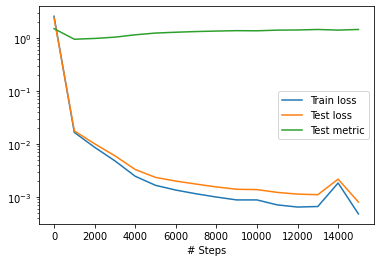

In [3]:
"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

def heat_eq_exact_solution(x, t, y, z):
    """Returns the exact solution for a given x and t (for sinusoidal initial conditions).
    Parameters
    ----------
    x : np.ndarray
    t : np.ndarray
    """
    res1 = np.exp(-(n**2 * np.pi**2 * a * t) / (L**2)) * np.sin(n * np.pi * x / L)
    res2 = np.exp(-(n**2 * np.pi**2 * a * z) / (L**2)) * np.sin(n * np.pi * y / L)
    return res1 * res2

def exact(x):
    """Returns the exact solution for a given x and t (for sinusoidal initial conditions).
    Parameters
    ----------
    x : np.ndarray
    t : np.ndarray
    """
    res1 = np.exp(-(n**2 * np.pi**2 * a * x[:, 1:2]) / (L**2)) * np.sin(n * np.pi * x[:, 0:1] / L)
    res2 = np.exp(-(n**2 * np.pi**2 * a * x[:, 3:4]) / (L**2)) * np.sin(n * np.pi * x[:, 2:3] / L)
    return np.hstack([0 * res1 * res2, res1 * res2])


# Problem parameters:
a = 0.4  # Thermal diffusivity
L = 1  # Length of the bar
n = 1  # Frequency of the sinusoidal initial conditions
k = 2

weights = [1000 for i in range(k)]
weights[0] = 1
print(weights)


def pde(x, y):
    """Expresses the PDE residual of the heat equation."""
    V0, V1 = y[:, 0:1], y[:, 1:2]
    dV0_t = dde.grad.jacobian(y, x, i=0, j=1)
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    
    dV1_z = dde.grad.jacobian(y, x, i=1, j=3)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dist = tf.abs(x[:, 0:1] - x[:, 2:3])** 2 
    F =  10 * tf.exp(- dist * 10) * tf.exp(- 2 * x[:, 1:2] - 2 * x[:, 3:4])

    return [dV0_t - a * dV0_xx - F, dV1_z - a * dV1_yy - V0]
    

def transform(x, y):
    V0, V1 = y[:, 0:1], y[:, 1:2]
    
    res1 = tf.sin(np.pi * x[:, 0:1]) 
    res2 = tf.sin(np.pi * x[:, 2:3]) 
    exp1 = tf.exp(- n ** 2 * np.pi ** 2 * a * x[:, 1:2])
    exp2 = tf.exp(- n ** 2 * np.pi ** 2 * a * x[:, 3:4])
    result = res1 * res2 * (exp1 * exp2   + (x[:, 1:2] + x[:, 3:4]) * V1) 
    return tf.concat([V0, result], axis=1)
    
    
# Computational geometry:
geom = dde.geometry.Interval(0, L)
timedomain = dde.geometry.TimeDomain(0, 1)
geomtime = dde.geometry.GeometryXTime(geom, timedomain)
Geom = GeometryXGeometry(geomtime,2)   

# Define the PDE problem and configurations of the network:
data = dde.data.TimePDE(
    Geom,
    pde,
    [],
    train_distribution = 'pseudo',
    num_domain = 4000,
    num_test = 4000,
    solution=exact,
)

def l2_error(y_true, y_pred):
    pred = y_true - y_pred
    return np.linalg.norm(pred[:, k-1:k])/np.linalg.norm(y_true[:, k-1:k]) 

#net = dde.nn.FNN([2 * k] + [20] * 3 + [1], "tanh", "Glorot normal")
net = dde.nn.FNN([2 * k] + [20] * 3 + [k], "tanh", "Glorot normal")
net.apply_output_transform(transform)

model = dde.Model(data, net)

# Build and train the model:
model.compile("adam", lr=1e-3, metrics=[l2_error])
losshistory, train_state = model.train(epochs=15000)

# Plot/print the results
dde.saveplot(losshistory, train_state, issave=True, isplot=True)


In [6]:
result = np.sum(
            [np.prod(v.get_shape().as_list()) for v in model.net.trainable_variables]
        )
print('Theta:= ', result)

Theta:=  982


In [9]:
u_sca.min(), u_sca.max()
#(0.0, 0.99974823)

(0.0, 0.99974823)

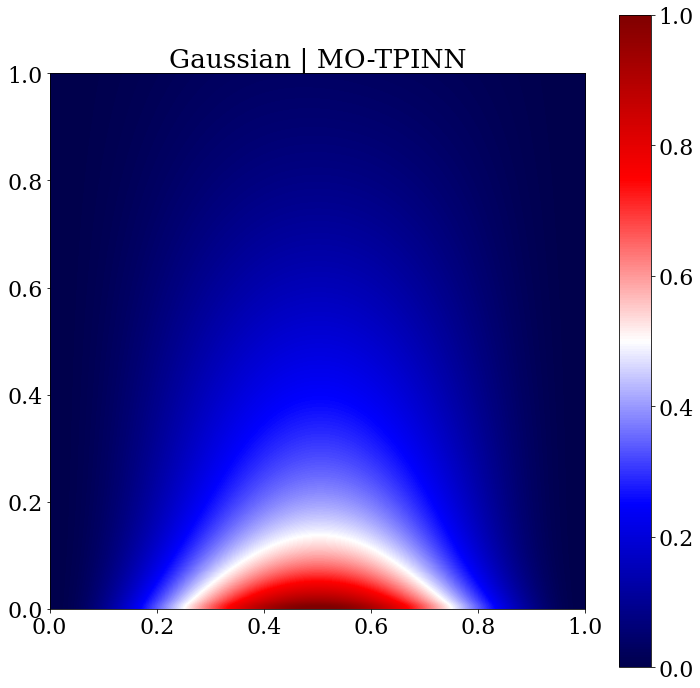

In [10]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

vmin = 0 
vmax = 1

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)[:, k-1:k]
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='MO-TPINNs', vmin=vmin, vmax=vmax)

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('Gaussian | MO-TPINN')
plt.savefig('Heat-Gaussian-MO.pdf')